# 09 · Time series: how fresh is Overture's building data?

The tract table has no time dimension, but every Overture building carries `sources[0].update_time` (when the contributing source record was last updated). Counting buildings by **month of last update** gives a genuine monthly time series per source and region.

**What the series means:** for OpenStreetMap-sourced buildings it is "how many footprints were last touched in month *t*", a proxy for mapping activity / recency. Old, unedited buildings pile up in the past, and the final month (2026-08) is partial because the release is dated 2026-08-19.

Covers: moving averages, exponential smoothing, regression forecasting, stationarity tests, ACF/PACF, ARMA / ARIMA / SARIMA / SARIMAX, and a note on neural sequence models.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow.parquet as pq, pyarrow.compute as pc
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name in ("notebooks", "analysis_scripts") else ROOT
DATA, OUT = ROOT / "data", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42; np.random.seed(SEED)
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 0 · Build the monthly series straight from the zip (cached)

19169789 buildings; {'OpenStreetMap': 1001, 'Microsoft ML Buildings': 128, 'Esri Community Maps': 5, 'Google Open Buildings': 2}


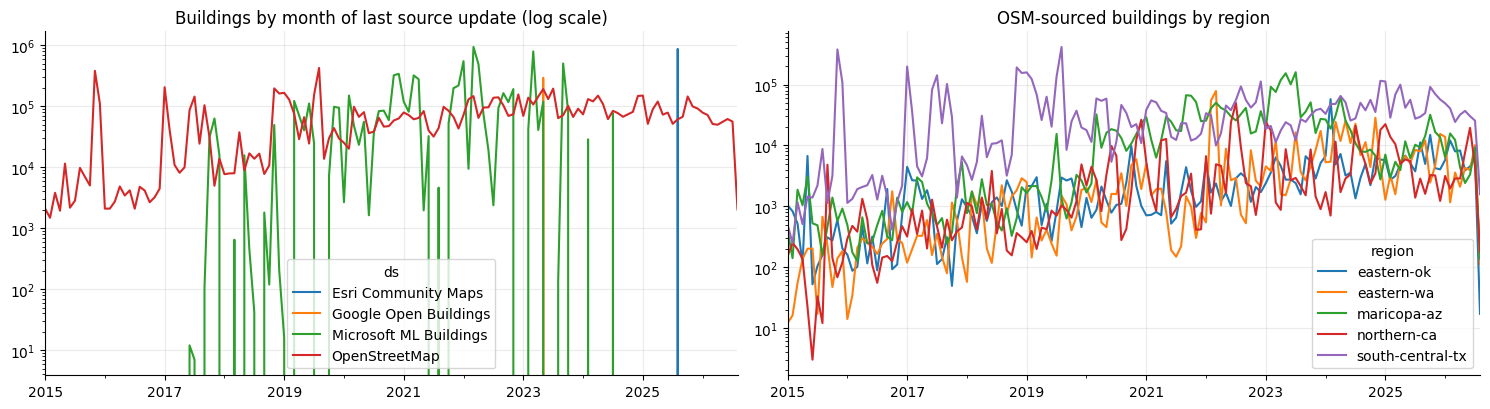

In [2]:
cache = OUT / "building_update_monthly.parquet"
if not cache.exists():
    z = zipfile.ZipFile(DATA / "reference.zip"); parts = []
    for r in ["eastern-wa", "northern-ca", "maricopa-az", "eastern-ok", "south-central-tx"]:
        with z.open(f"reference/{r}/{r}-overture-buildings.parquet") as fh:       # stored member: read row group by row group
            pf = pq.ParquetFile(fh)
            for g in range(pf.metadata.num_row_groups):
                s = pc.list_element(pf.read_row_group(g, columns=["sources"])["sources"], 0)
                d = pd.DataFrame({"ds": pc.struct_field(s, "dataset").to_pandas(),
                                  "ym": pc.utf8_slice_codeunits(pc.struct_field(s, "update_time"), 0, 7).to_pandas()})
                c = d.groupby(["ds", "ym"], dropna=False).size().reset_index(name="n"); c["region"] = r; parts.append(c)
    pd.concat(parts).groupby(["region", "ds", "ym"], dropna=False).n.sum().reset_index().to_parquet(cache)
raw = pd.read_parquet(cache); raw["month"] = pd.PeriodIndex(raw.ym, freq="M")
print(raw.n.sum(), "buildings;", raw.ds.value_counts().to_dict())
piv = raw[raw.month >= "2015-01"].pivot_table(index="month", columns="ds", values="n", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
piv.plot(ax=ax[0], logy=True); ax[0].set_title("Buildings by month of last source update (log scale)"); ax[0].set_xlabel("")
raw[(raw.ds == "OpenStreetMap") & (raw.month >= "2015-01")].pivot_table(index="month", columns="region", values="n", aggfunc="sum").plot(ax=ax[1], logy=True)
ax[1].set_title("OSM-sourced buildings by region"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Comment:** OSM edits appear in almost every month (1,001 region-month cells), while Microsoft records sit in only 128 region-months and Esri/Google in a handful: they are one-off import batches, not an ongoing process. Only the OSM series behaves like a continuing flow, so that is the one we forecast.

## 1 · The series: OSM buildings last edited per month, 2015-01 to 2026-07

139 months; min 1,481  median 64,107  max 423,464


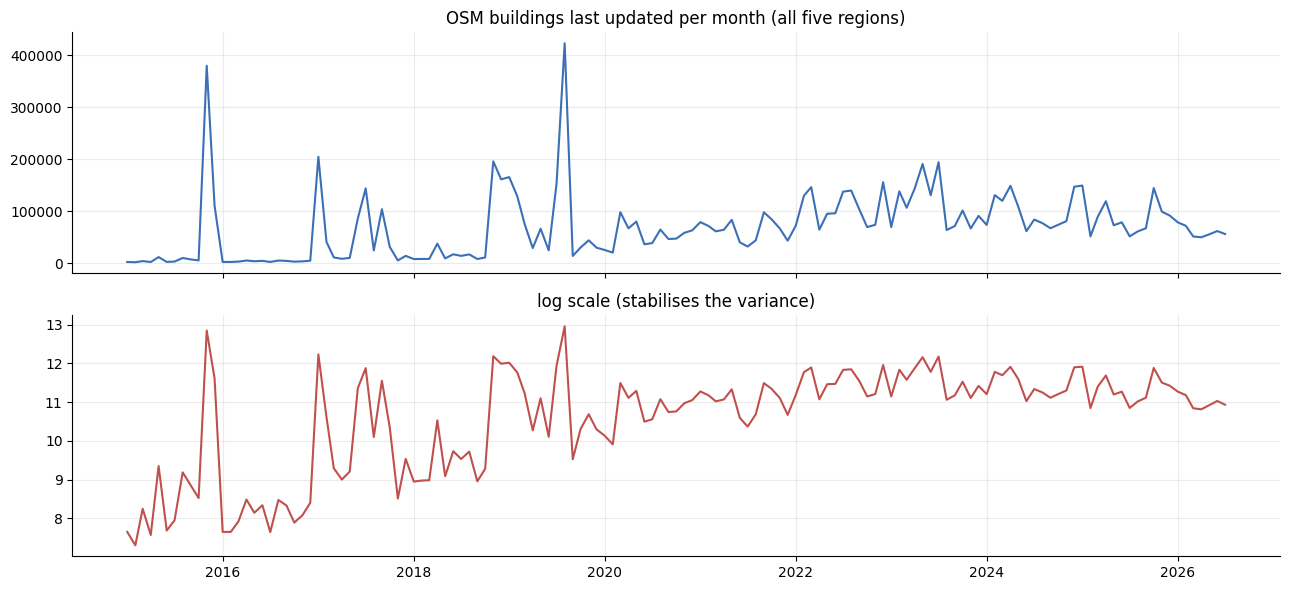

In [3]:
y = piv["OpenStreetMap"].loc["2015-01":"2026-07"]; y.index = y.index.to_timestamp(); y = y.asfreq("MS")
ly = np.log(y)
print(len(y), "months;", f"min {int(y.min()):,}  median {int(y.median()):,}  max {int(y.max()):,}")
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(y, color="#3b6fb6"); ax[0].set_title("OSM buildings last updated per month (all five regions)")
ax[1].plot(ly, color="#c0504d"); ax[1].set_title("log scale (stabilises the variance)")
plt.tight_layout(); plt.show()

**Comment:** monthly counts range from about 1.5k to 423k, rising until roughly 2020 and broadly flat since, with large spikes; the log scale tames the variance, so we model `log(count)`.

## 2 · Moving averages and exponential smoothing

holdout RMSE on log scale:
SES                            0.302
naive (last value)             0.434
Holt (trend)                   0.443
seasonal naive                 0.458
Holt-Winters (trend+season)    0.489


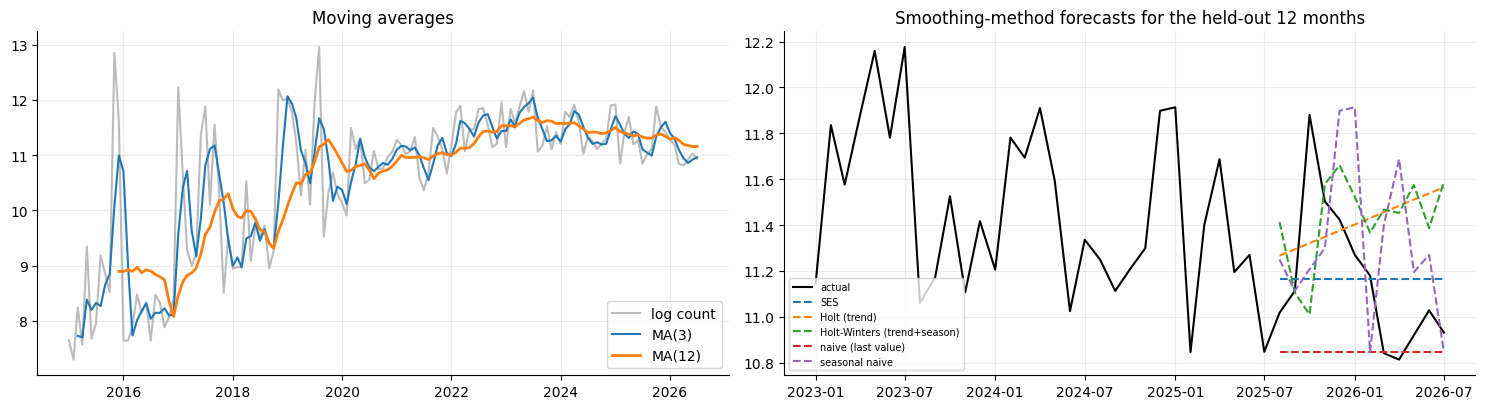

In [4]:
train, test = ly.iloc[:-12], ly.iloc[-12:]          # hold out the last 12 months
ma3 = ly.rolling(3).mean(); ma12 = ly.rolling(12).mean()
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
holt = ExponentialSmoothing(train, trend="add", initialization_method="estimated").fit()
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit()
fc = {"SES": ses.forecast(12), "Holt (trend)": holt.forecast(12), "Holt-Winters (trend+season)": hw.forecast(12)}
fc["naive (last value)"] = pd.Series(train.iloc[-1], index=test.index)
fc["seasonal naive"] = pd.Series(train.iloc[-12:].values, index=test.index)
res = pd.Series({k: rmse(v, test) for k, v in fc.items()}).sort_values()
print("holdout RMSE on log scale:\n" + res.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].plot(ly, color="#bbb", label="log count"); ax[0].plot(ma3, label="MA(3)"); ax[0].plot(ma12, label="MA(12)", lw=2); ax[0].legend(); ax[0].set_title("Moving averages")
ax[1].plot(ly["2023":], color="k", label="actual")
for k, v in fc.items(): ax[1].plot(v, label=k, ls="--")
ax[1].legend(fontsize=7); ax[1].set_title("Smoothing-method forecasts for the held-out 12 months")
plt.tight_layout(); plt.show()

**Comment:** MA(3) follows the noise; MA(12) shows the trend. On the 12-month holdout, plain simple exponential smoothing wins (log RMSE 0.30); adding a trend (0.44) or seasonality (0.49) makes it *worse*, and seasonal-naive (0.46) is worse than naive, so there is no usable annual cycle.

## 3 · Regression for forecasting (trend + month-of-year dummies)

R2 = 0.511   holdout RMSE = 1.231   trend per year = +0.317 log points


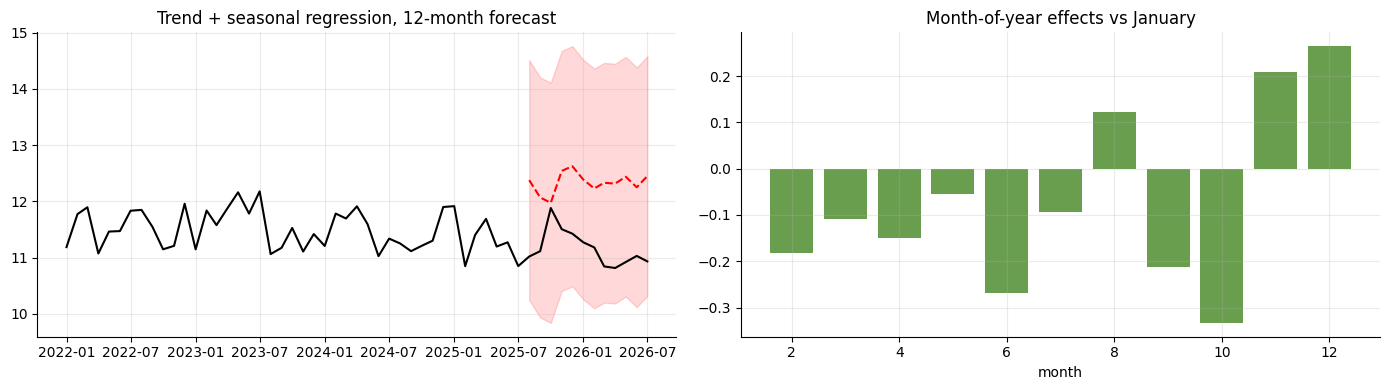

In [5]:
df = pd.DataFrame({"y": ly}); df["t"] = np.arange(len(df)); df["m"] = df.index.month
tr_df, te_df = df.iloc[:-12], df.iloc[-12:]
reg = smf.ols("y ~ t + C(m)", tr_df).fit()
pred = reg.get_prediction(te_df).summary_frame(alpha=.05)
print(f"R2 = {reg.rsquared:.3f}   holdout RMSE = {rmse(pred['mean'], te_df.y):.3f}   trend per year = {reg.params['t'] * 12:+.3f} log points")
seas = reg.params.filter(like="C(m)").reindex([f"C(m)[T.{i}]" for i in range(2, 13)]).values
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ly["2022":], color="k"); ax[0].plot(pred["mean"], "r--"); ax[0].fill_between(pred.index, pred.obs_ci_lower, pred.obs_ci_upper, color="r", alpha=.15); ax[0].set_title("Trend + seasonal regression, 12-month forecast")
ax[1].bar(range(2, 13), seas, color="#6a9e4f"); ax[1].set_title("Month-of-year effects vs January"); ax[1].set_xlabel("month")
plt.tight_layout(); plt.show()

**Comment:** the in-sample fit is modest (R2 = 0.51) and the holdout RMSE is 1.23, four times worse than SES. Extrapolating a straight line (+0.32 log points per year) fails when the recent level departs from the long-run trend; the month-of-year bars are small and noisy, consistent with no real seasonality.

## 4 · Stationarity: ADF / KPSS, differencing, ACF / PACF
ADF: H0 = unit root (non-stationary). KPSS: H0 = stationary. We want ADF to reject and KPSS not to reject.

C:\Users\prajw\AppData\Local\Temp\ipykernel_19904\2113782034.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  a = adfuller(x.dropna(), autolag="AIC")[1]; k = kpss(x.dropna(), regression="c", nlags="auto")[1]
C:\Users\prajw\AppData\Local\Temp\ipykernel_19904\2113782034.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  a = adfuller(x.dropna(), autolag="AIC")[1]; k = kpss(x.dropna(), regression="c", nlags="auto")[1]
C:\Users\prajw\AppData\Local\Temp\ipykernel_19904\2113782034.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  a = adfuller(x.dropna(), autolag="AIC")[1]; k = kpss(x.dropna(), regression="c", nlags="auto")[1]


               series  ADF p (reject => stationary)  KPSS p (reject => NON-stationary)
            log level                        0.1973                             0.0100
     first difference                        0.0000                             0.0667
   seasonal diff (12)                        0.0003                             0.1000
first + seasonal diff                        0.0000                             0.1000


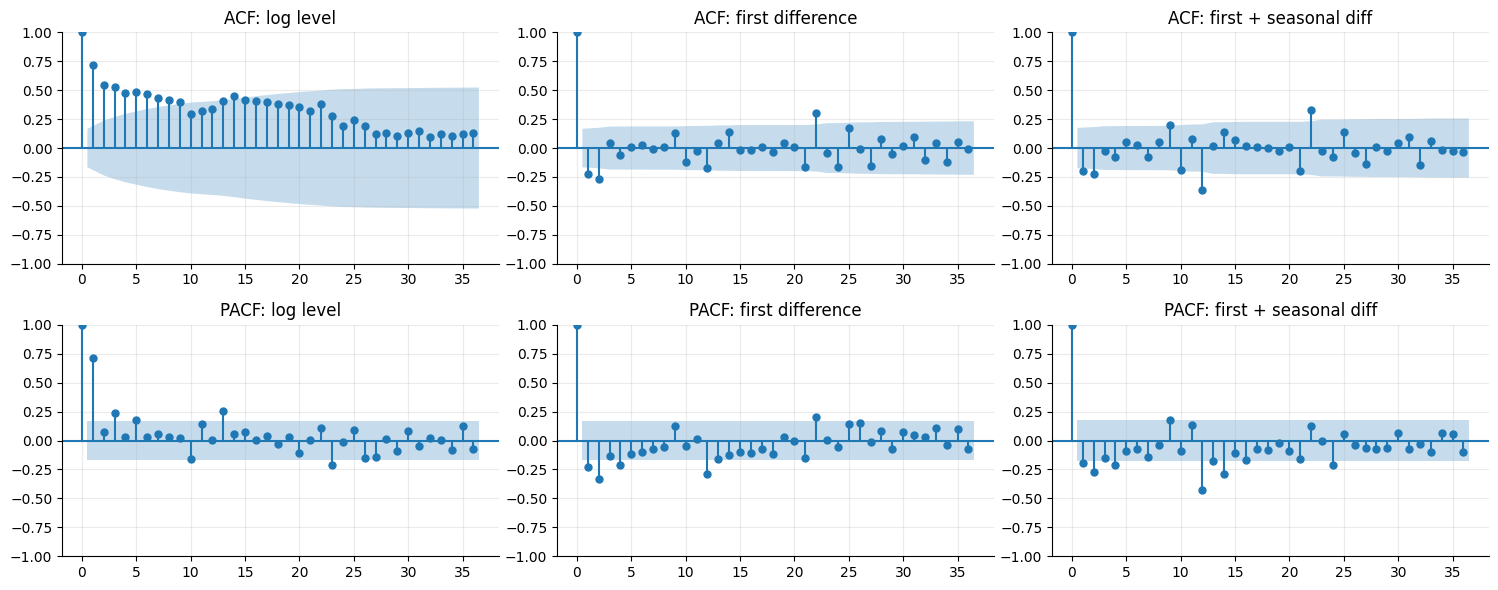

In [6]:
def tests(x, name):
    a = adfuller(x.dropna(), autolag="AIC")[1]; k = kpss(x.dropna(), regression="c", nlags="auto")[1]
    return {"series": name, "ADF p (reject => stationary)": a, "KPSS p (reject => NON-stationary)": k}
d1 = ly.diff().dropna(); d12 = ly.diff(12).dropna(); d1_12 = ly.diff().diff(12).dropna()
print(pd.DataFrame([tests(ly, "log level"), tests(d1, "first difference"), tests(d12, "seasonal diff (12)"), tests(d1_12, "first + seasonal diff")]).round(4).to_string(index=False))
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, (x, nm) in enumerate([(ly, "log level"), (d1, "first difference"), (d1_12, "first + seasonal diff")]):
    plot_acf(x, lags=36, ax=ax[0, j], title=f"ACF: {nm}"); plot_pacf(x, lags=36, ax=ax[1, j], method="ywm", title=f"PACF: {nm}")
plt.tight_layout(); plt.show()

**Comment:** the log level is non-stationary (ADF p = 0.20 does not reject a unit root; KPSS p = 0.01 rejects stationarity). After one difference ADF rejects (p < 0.001) and KPSS no longer rejects at 5% (p = 0.067), so d = 1 is enough. The ACF/PACF of the differenced series are the guide for the AR / MA orders tried next.

## 5 · ARMA, ARIMA, SARIMA, SARIMAX
All fitted on the first 12-month-held-out split, compared by AIC and holdout RMSE.

                             AIC  holdout RMSE (log)
model                                               
ARMA(2,1) on d1              NaN               0.769
ARIMA(1,1,1)             337.800               0.327
ARIMA(2,1,2)             335.753               0.329
SARIMA(1,1,1)(1,1,1,12)  339.426               0.798
SARIMAX + exog (MSFT)    339.798               0.326


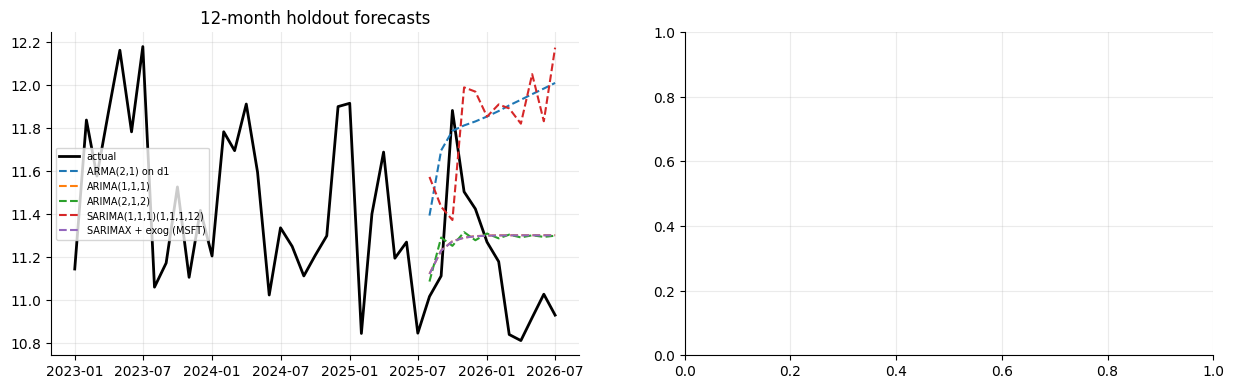

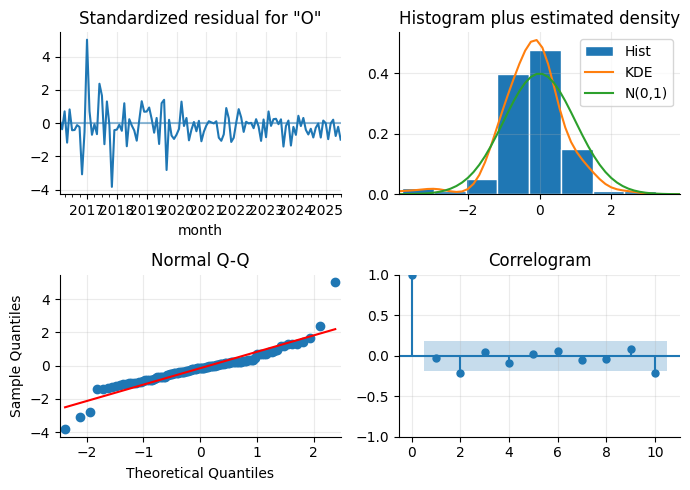

In [7]:
exog = np.log1p(piv["Microsoft ML Buildings"].loc["2015-01":"2026-07"]); exog.index = exog.index.to_timestamp(); exog = exog.asfreq("MS").to_frame("msft")
specs = {
 "ARMA(2,1) on d1":         lambda: ARIMA(train.diff().dropna(), order=(2, 0, 1)),
 "ARIMA(1,1,1)":            lambda: ARIMA(train, order=(1, 1, 1)),
 "ARIMA(2,1,2)":            lambda: ARIMA(train, order=(2, 1, 2)),
 "SARIMA(1,1,1)(1,1,1,12)": lambda: SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)),
 "SARIMAX + exog (MSFT)":   lambda: SARIMAX(train, exog=exog.loc[train.index], order=(1, 1, 1), seasonal_order=(0, 0, 0, 0)),
}
rows, fcs = [], {}
for name, mk in specs.items():
    m = mk().fit(disp=False) if "SARIMAX" in name or "SARIMA" in name else mk().fit()
    if name.startswith("ARMA"):
        f_ = m.forecast(12).cumsum() + train.iloc[-1]
    elif "exog" in name:
        f_ = m.forecast(12, exog=exog.loc[test.index])
    else:
        f_ = m.forecast(12)
    f_.index = test.index; fcs[name] = f_
    rows.append((name, m.aic if not name.startswith("ARMA") else np.nan, rmse(f_, test)))
tab = pd.DataFrame(rows, columns=["model", "AIC", "holdout RMSE (log)"]).set_index("model")
print(tab.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].plot(ly["2023":], color="k", lw=2, label="actual")
for k, v in fcs.items(): ax[0].plot(v, ls="--", label=k)
ax[0].legend(fontsize=7); ax[0].set_title("12-month holdout forecasts")
best = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
best.plot_diagnostics(fig=plt.figure(figsize=(7, 5)))
plt.tight_layout(); plt.show()

**Comment:** ARIMA(1,1,1), ARIMA(2,1,2) and the SARIMAX with Microsoft exog all land at log RMSE about 0.33; the exog term adds nothing. The seasonal SARIMA is much worse (0.80) and the differenced ARMA is worse again (0.77): seasonality and over-differencing hurt on a series with no annual cycle. AIC differences between the non-seasonal models are tiny.

## 6 · Neural sequence models: pros and cons (discussion)

| | Pros | Cons for *this* series |
|---|---|---|
| LSTM / GRU / Transformer | learn non-linear dynamics, handle many related series and covariates at once, no stationarity assumption | only ~140 monthly points: far too few to train a network |
| | multi-horizon outputs, can pool the five regions | no uncertainty intervals out of the box; hard to explain; many hyper-parameters |
| ARIMA / ETS | well-calibrated intervals, interpretable, strong with short series | linear, one series at a time |

With 139 observations a classical model is the right tool. A neural sequence model would only pay off if we modelled *many* series jointly (every tract-month), which the tract table does not give us.

## 7 · Case-study summary

Best holdout model: SARIMAX + exog (MSFT) (log RMSE 0.326, i.e. about 39% typical error)


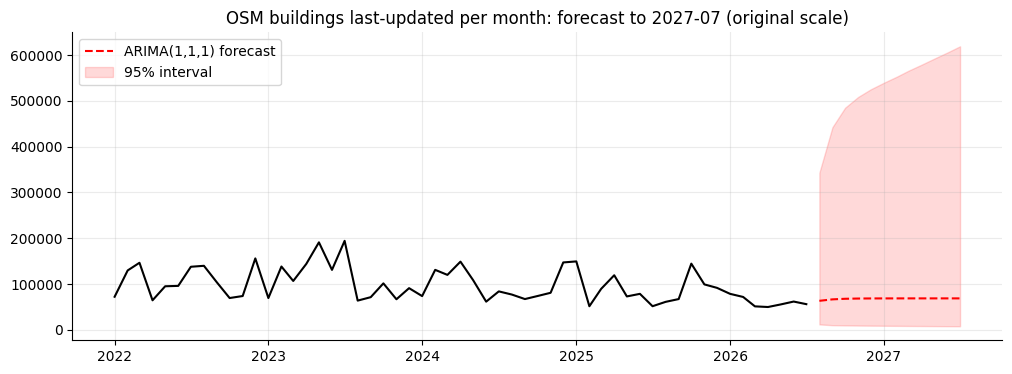

In [8]:
best_name = tab["holdout RMSE (log)"].idxmin()
print(f"Best holdout model: {best_name} (log RMSE {tab['holdout RMSE (log)'].min():.3f}, i.e. about {100 * (np.exp(tab['holdout RMSE (log)'].min()) - 1):.0f}% typical error)")
fut = ARIMA(ly, order=(1, 1, 1)).fit().get_forecast(12).summary_frame()
fut.index = pd.date_range(ly.index[-1] + pd.offsets.MonthBegin(), periods=12, freq="MS")
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(np.exp(ly["2022":]), color="k"); ax.plot(np.exp(fut["mean"]), "r--", label="ARIMA(1,1,1) forecast")
ax.fill_between(fut.index, np.exp(fut.mean_ci_lower), np.exp(fut.mean_ci_upper), color="r", alpha=.15, label="95% interval"); ax.legend(); ax.set_title("OSM buildings last-updated per month: forecast to 2027-07 (original scale)")
plt.show()

**Comment:** overall, simple exponential smoothing (0.30) is the best forecaster and ARIMA(1,1,1) (0.33) is close; extra complexity does not help with 139 points. The ARIMA forecast is a nearly flat level with a wide interval, which is the honest answer for a noisy, unseasonal series. Context for the bias question: low edit activity means map data ages fastest.